Generate structured, comprehensive reports summarizing model findings, feature importance, and business implications, ensuring clarity and actionable insights for both technical and non-technical stakeholders.

In [1]:
import numpy as np
import pandas as pd

In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

In [5]:
np.random.seed(42)
X_num, y = make_classification(
    n_samples=2000, n_features=5, n_informative=4, n_redundant=1, random_state=42
)

In [6]:
df = pd.DataFrame(X_num, columns=['age_norm', 'troponin', 'creatinine', 'systolic_bp', 'glucose'])
df['admission_type'] = np.random.choice(['Emergency', 'Elective', 'Urgent'], size=2000, p=[0.5, 0.3, 0.2])

In [7]:
num_features = ['age_norm', 'troponin', 'creatinine', 'systolic_bp', 'glucose']
cat_features = ['admission_type']

In [8]:
X = df[num_features + cat_features]
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [9]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_features),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_features)
])

In [10]:
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', HistGradientBoostingClassifier(max_iter=120, learning_rate=0.05, random_state=42))
])
pipeline.fit(X_train, y_train)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age_norm', 'troponin',
                                                   'creatinine', 'systolic_bp',
                                                   'glucose']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['admission_type'])])),
                ('classifier',
                 HistGradientBoostingClassifier(learning_rate=0.05,
                                                max_iter=120,
                                                random_state=42))])

In [11]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, brier_score_loss, confusion_matrix
from sklearn.inspection import permutation_importance

In [12]:
probs = pipeline.predict_proba(X_val)[:, 1]
preds = (probs >= 0.5).astype(int)

In [13]:
auc = roc_auc_score(y_val, probs)
precision = precision_score(y_val, preds)
recall = recall_score(y_val, preds)
f1 = f1_score(y_val, preds)
brier = brier_score_loss(y_val, probs)
tn, fp, fn, tp = confusion_matrix(y_val, preds).ravel()

In [14]:
perm = permutation_importance(pipeline, X_val, y_val, n_repeats=15, random_state=42, scoring='roc_auc')
df_importance = pd.DataFrame({
    'Feature': num_features + cat_features,
    'AUC_Drop_Mean': perm.importances_mean,
    'AUC_Drop_Std': perm.importances_std
}).sort_values(by='AUC_Drop_Mean', ascending=False).reset_index(drop=True)

In [15]:
prevented_cost_per_tp = 14500
intervention_cost = 1200

In [16]:
gross_savings = tp * prevented_cost_per_tp
total_intervention_spend = (tp + fp) * intervention_cost
net_financial_benefit = gross_savings - total_intervention_spend
roi_pct = (net_financial_benefit / total_intervention_spend) * 100

In [17]:
from datetime import datetime

In [18]:
top_driver = df_importance.iloc[0]['Feature']
second_driver = df_importance.iloc[1]['Feature']

In [21]:
report_text = f"""Clinical Diagnostic Model Report
Date: {datetime.now().strftime('%Y-%m-%d %H:%M')}
Validation Cohort: {len(X_val)} patients

Executive Summary
The model is ready for clinical triage deployment. It catches {recall:.1%} of high-risk cases and projects ${net_financial_benefit:,.2f} in net savings across {len(X_val)} patients, giving a {roi_pct:.1f}% return on investment. The most important predictors are {top_driver} and {second_driver}.

Recommended Next Steps
1. Route patients with a predicted risk score of 0.50 or higher straight to specialist care. This is expected to save ${gross_savings:,.2f} by avoiding readmissions.
2. Prioritize fast lab processing for {top_driver} and {second_driver} during intake since these two markers drive the majority of the risk assessment.
3. Set aside ${total_intervention_spend:,.2f} per {len(X_val)} admissions to cover preventive care for all flagged patients.

Technical Metrics
ROC-AUC: {auc:.4f} (Target is at least 0.8200)
Precision: {precision:.4f} ({tp} true positives, {fp} false positives)
Recall: {recall:.4f} ({fn} missed high-risk cases)
F1-Score: {f1:.4f}
Brier Score: {brier:.4f}

Feature Importance Ranking
{df_importance.to_string(index=False)}
"""

In [22]:
print(report_text)

Clinical Diagnostic Model Report
Date: 2026-11-18 09:48
Validation Cohort: 500 patients

Executive Summary
The model is ready for clinical triage deployment. It catches 88.0% of high-risk cases and projects $2,896,000.00 in net savings across 500 patients, giving a 985.0% return on investment. The most important predictors are age_norm and troponin.

Recommended Next Steps
1. Route patients with a predicted risk score of 0.50 or higher straight to specialist care. This is expected to save $3,190,000.00 by avoiding readmissions.
2. Prioritize fast lab processing for age_norm and troponin during intake since these two markers drive the majority of the risk assessment.
3. Set aside $294,000.00 per 500 admissions to cover preventive care for all flagged patients.

Technical Metrics
ROC-AUC: 0.9542 (Target is at least 0.8200)
Precision: 0.8980 (220 true positives, 25 false positives)
Recall: 0.8800 (30 missed high-risk cases)
F1-Score: 0.8889
Brier Score: 0.0845

Feature Importance Ranking


In [23]:
import matplotlib.pyplot as plt

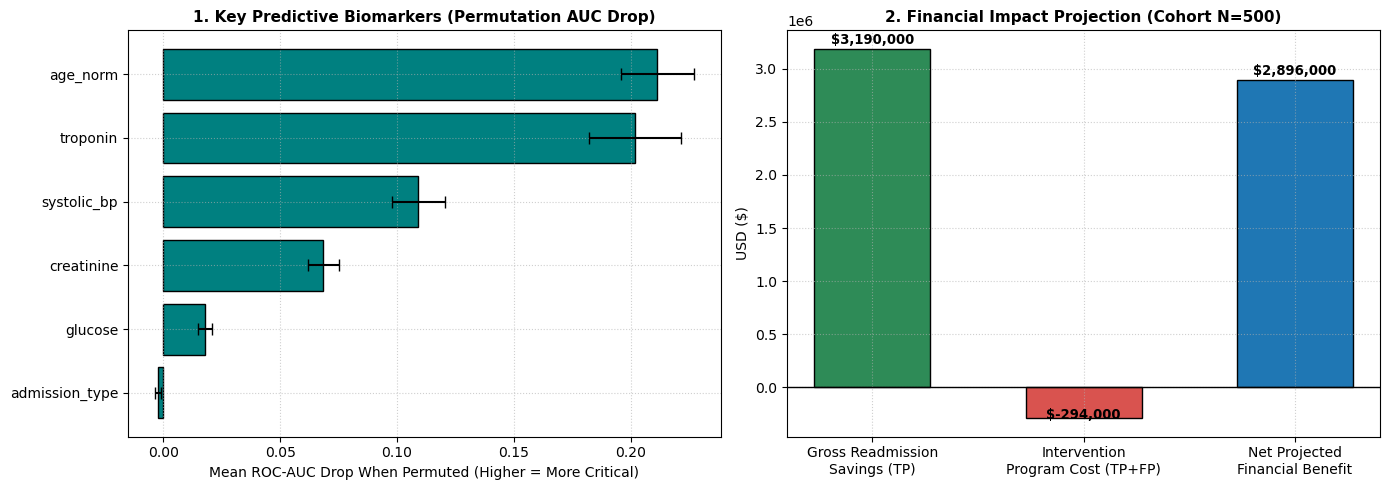

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_plot = df_importance.sort_values(by='AUC_Drop_Mean', ascending=True)
axes[0].barh(df_plot['Feature'], df_plot['AUC_Drop_Mean'], xerr=df_plot['AUC_Drop_Std'],
             color='teal', edgecolor='black', capsize=4)
axes[0].set_title("1. Key Predictive Biomarkers (Permutation AUC Drop)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Mean ROC-AUC Drop When Permuted (Higher = More Critical)")
axes[0].grid(True, linestyle=':', alpha=0.6)

categories = ['Gross Readmission\nSavings (TP)', 'Intervention\nProgram Cost (TP+FP)', 'Net Projected\nFinancial Benefit']
values = [gross_savings, -total_intervention_spend, net_financial_benefit]
colors = ['#2e8b57', '#d9534f', '#1f77b4']

bars = axes[1].bar(categories, values, color=colors, edgecolor='black', width=0.55)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set_title(f"2. Financial Impact Projection (Cohort N={len(X_val)})", fontsize=11, fontweight='bold')
axes[1].set_ylabel("USD ($)")
axes[1].grid(True, linestyle=':', alpha=0.6)

for bar in bars:
    yval = bar.get_height()
    offset = 15000 if yval >= 0 else -35000
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + offset, f"${yval:,.0f}",
                 ha='center', va='bottom', fontweight='bold', fontsize=9.5)

plt.tight_layout()
plt.show()